In [ ]:
import os
import zipfile
import numpy as np
from scipy.special import gamma as gamma_func
import matplotlib.pyplot as plt
import matplotlib.patches as patches

os.makedirs('fig', exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 10.5,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 8.5,
    'legend.frameon': False,
    'axes.linewidth': 0.8,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
    'savefig.bbox': 'tight',
    'figure.dpi': 150
})

# Paleta Okabe-Ito (daltonismo-segura)
OI_BLUE   = '#0072B2'
OI_ORANGE = '#D55E00'
OI_GREEN  = '#009E73'
OI_PINK   = '#CC79A7'
OI_CYAN   = '#56B4E9'
OI_YELLOW = '#E69F00'
OI_BLACK  = '#111111'

print("✅ Entorno Colab-ESQUEMAS configurado. Carpeta /content/fig lista.")

✅ Entorno Colab-ESQUEMAS configurado. Carpeta /content/fig lista.


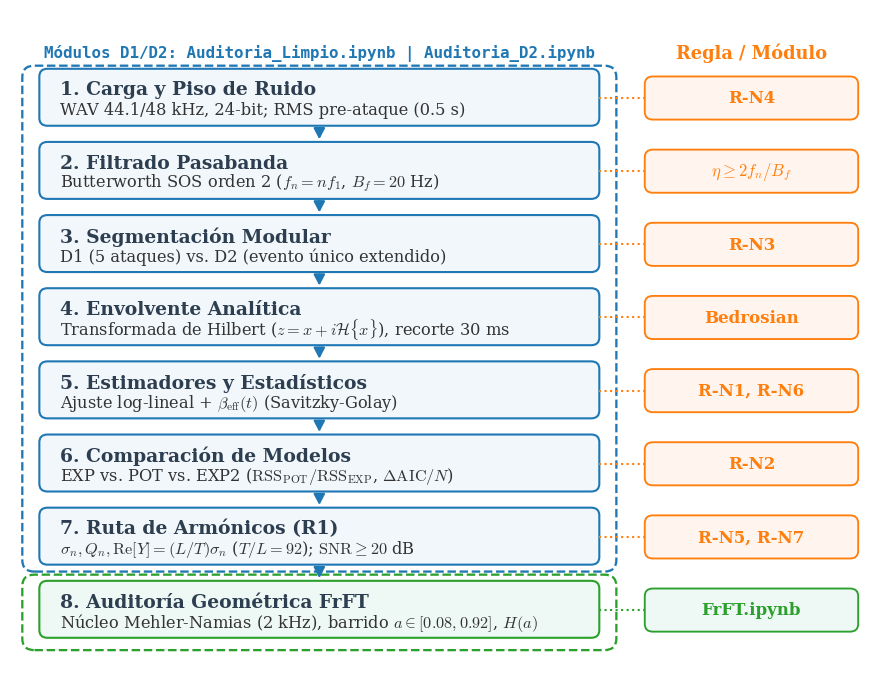

✅ [E1] Corregida y guardada: fig/Fig_5_3_Pipeline.pdf


In [ ]:
fig, ax = plt.subplots(figsize=(7.4, 5.8))
ax.set_xlim(0, 10.6)
ax.set_ylim(0, 8.7)
ax.axis('off')

etapas = [
    ("1. Carga y Piso de Ruido", "WAV 44.1/48 kHz, 24-bit; RMS pre-ataque (0.5 s)", "R-N4", 7.6),
    ("2. Filtrado Pasabanda", r"Butterworth SOS orden 2 ($f_n = n f_1$, $B_f = 20$ Hz)", r"$\eta \geq 2f_n/B_f$", 6.65),
    ("3. Segmentación Modular", "D1 (5 ataques) vs. D2 (evento único extendido)", "R-N3", 5.7),
    ("4. Envolvente Analítica", r"Transformada de Hilbert ($z = x + i\mathcal{H}\{x\}$), recorte 30 ms", "Bedrosian", 4.75),
    ("5. Estimadores y Estadísticos", r"Ajuste log-lineal + $\beta_{\mathrm{eff}}(t)$ (Savitzky-Golay)", "R-N1, R-N6", 3.8),
    ("6. Comparación de Modelos", r"EXP vs. POT vs. EXP2 ($\mathrm{RSS}_{\mathrm{POT}}/\mathrm{RSS}_{\mathrm{EXP}}$, $\Delta\mathrm{AIC}/N$)", "R-N2", 2.85),
    ("7. Ruta de Armónicos (R1)", r"$\sigma_n, Q_n, \mathrm{Re}[Y]=(L/T)\sigma_n$ ($T/L=92$); $\mathrm{SNR}\geq 20$ dB", "R-N5, R-N7", 1.9),
    ("8. Auditoría Geométrica FrFT", r"Núcleo Mehler-Namias (2 kHz), barrido $a \in [0.08, 0.92]$, $H(a)$", "FrFT.ipynb", 0.95)
]

# Contenedor Etapas 1-7 (D1 y D2)
brace_main = patches.FancyBboxPatch((0.15, 1.52), 7.20, 6.45,
                                    boxstyle="round,pad=0.06,rounding_size=0.15",
                                    linewidth=1.1, edgecolor=OI_BLUE, facecolor='none', ls='--')
ax.add_patch(brace_main)
ax.text(3.75, 8.20, "Módulos D1/D2: Auditoria_Limpio.ipynb | Auditoria_D2.ipynb",
        fontsize=7.6, fontweight='bold', color=OI_BLUE, ha='center', va='center', family='monospace')

# Contenedor Etapa 8 (FrFT)
brace_frft = patches.FancyBboxPatch((0.15, 0.50), 7.20, 0.86,
                                    boxstyle="round,pad=0.06,rounding_size=0.15",
                                    linewidth=1.1, edgecolor=OI_GREEN, facecolor='none', ls='--')
ax.add_patch(brace_frft)

for titulo, desc, regla, y in etapas:
    edge_c = OI_GREEN if "FrFT" in titulo else OI_BLUE
    face_c = '#eef9f5' if "FrFT" in titulo else '#f2f7fb'

    box = patches.FancyBboxPatch((0.35, y - 0.30), 6.80, 0.64,
                                 boxstyle="round,pad=0.05,rounding_size=0.10",
                                 linewidth=1.0, edgecolor=edge_c, facecolor=face_c)
    ax.add_patch(box)
    ax.text(0.55, y + 0.12, titulo, fontsize=9.0, fontweight='bold', color=OI_BLACK, va='center')
    ax.text(0.55, y - 0.14, desc, fontsize=7.8, color='#333333', va='center')

    r_edge = OI_GREEN if "FrFT" in regla else OI_ORANGE
    r_face = '#eef9f5' if "FrFT" in regla else '#fff5ee'
    rbox = patches.FancyBboxPatch((7.80, y - 0.23), 2.55, 0.48,
                                  boxstyle="round,pad=0.04,rounding_size=0.1",
                                  linewidth=0.9, edgecolor=r_edge, facecolor=r_face)
    ax.add_patch(rbox)
    ax.text(9.075, y + 0.01, regla, fontsize=8.0, fontweight='bold', color=r_edge,
            ha='center', va='center')

    ax.plot([7.20, 7.75], [y + 0.01, y + 0.01], color=r_edge, lw=1.0, ls=':')

for i in range(len(etapas) - 1):
    y_top = etapas[i][3] - 0.33
    y_bot = etapas[i+1][3] + 0.37
    ax.annotate('', xy=(3.75, y_bot), xytext=(3.75, y_top),
                arrowprops=dict(arrowstyle='-|>,head_length=0.42,head_width=0.22',
                                color=OI_BLUE, lw=1.1))

ax.text(9.075, 8.20, "Regla / Módulo", ha='center', va='center',
        fontsize=8.5, fontweight='bold', color=OI_ORANGE)

plt.savefig('fig/Fig_5_3_Pipeline.pdf')
plt.savefig('fig/Fig_5_3_Pipeline_preview.png', dpi=300)
plt.show()
print("✅ [E1] Corregida y guardada: fig/Fig_5_3_Pipeline.pdf")

In [ ]:
t = np.linspace(0.05, 6.0, 600)
w1 = 2 * np.pi * 196.0  # 1231.504 rad/s

alphas = [0.4, 0.6, 0.8]
sigmas = [1.0, 4.0]
colores = [OI_BLUE, OI_ORANGE, OI_GREEN]
estilos = ['-', '--']

fig, ax = plt.subplots(figsize=(6.4, 3.8))

for sig, ls in zip(sigmas, estilos):
    for alpha, col in zip(alphas, colores):
        gamma_max = 2.0 * sig * (w1 ** (1.0 - alpha)) / np.sin(np.pi * alpha / 2.0)
        R_t = (alpha * (alpha + 1.0) * gamma_max / ((w1 ** 4) * gamma_func(1.0 - alpha))) * (t ** (-(alpha + 2.0))) * np.exp(sig * t)
        log10_R = np.log10(R_t)
        ax.plot(t, log10_R, color=col, ls=ls, lw=1.6,
                label=rf'$\alpha={alpha:.1f},\ \sigma_1={sig:.0f}\ \mathrm{{s}}^{{-1}}$')

# Líneas de referencia crítica
ax.axhline(0.0, color=OI_BLACK, lw=1.2, ls='-')
ax.text(0.15, 0.35, r'Umbral de cruce cola = polo ($R(t) = 1$)', fontsize=8.5, fontweight='bold', color=OI_BLACK)

ax.axvline(0.85, color=OI_PINK, lw=1.3, ls=':')
ax.text(0.92, -11.2, 'Fin ventana D1\n($t = 0.85$ s)', fontsize=8, color=OI_PINK, fontweight='bold')

ax.axvline(5.0, color='#555555', lw=1.3, ls=':')
ax.text(4.15, -11.2, 'Cruce D2\n($t^* \\approx 5$ s)', fontsize=8, color='#444444', fontweight='bold')

# Sombreado de región inaccesible bajo ruido
ax.axhspan(-13, 0, color='#eeeeee', alpha=0.55, zorder=0)
ax.text(2.4, -3.2, 'Región sub-umbral ($R(t) < 1$)\nCola apantallada por el polo / piso de ruido',
        fontsize=8.5, style='italic', color='#555555', ha='center')

ax.set_xlabel(r'Tiempo $t$ (s)')
ax.set_ylabel(r'$\log_{10} R(t)$ (razón cola/polo en aceleración)')
ax.set_xlim(0.05, 6.0)
ax.set_ylim(-12.5, 2.5)
ax.legend(loc='upper left', ncol=2, fontsize=8.0)

plt.savefig('fig/Fig_B_1_Cota_R.pdf')
plt.savefig('fig/Fig_B_1_Cota_R_preview.png', dpi=300)
plt.show()
print("✅ [E2] Guardada: fig/Fig_B_1_Cota_R.pdf")

In [ ]:
fig, (ax_lat, ax_sup) = plt.subplots(2, 1, figsize=(6.8, 4.6), gridspec_kw={'height_ratios': [1.25, 1.0]})

# -------------------------------------------------------------------------
# Panel (a): Vista Lateral (Corte Longitudinal)
# -------------------------------------------------------------------------
ax_lat.set_xlim(-5, 85)
ax_lat.set_ylim(-2, 24)
ax_lat.axis('off')
ax_lat.text(0, 22.2, '(a) Vista lateral (alzado)', fontsize=9.5, fontweight='bold', color=OI_BLACK)

# Base de concreto/granito (80 x 8 cm)
base_lat = patches.Rectangle((0, 2), 80, 8, linewidth=1.3, edgecolor=OI_BLACK, facecolor='#d9d9d9', hatch='///')
ax_lat.add_patch(base_lat)
ax_lat.text(40, 6, 'Base de alta impedancia (concreto / granito: 80 × 20 × 8 cm)',
            ha='center', va='center', fontsize=8.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.85))

# Varillas de acero Ø10 mm (embebidas 4.5 cm, sobresalen 1.5 cm) en x=7.5 y x=72.5 (L=65.0 cm)
x_izq, x_der = 7.5, 72.5
for xv in [x_izq, x_der]:
    varilla = patches.Rectangle((xv - 0.5, 5.5), 1.0, 6.0, linewidth=1.1, edgecolor=OI_BLACK, facecolor=OI_CYAN)
    ax_lat.add_patch(varilla)

# Cuerda EJ49 G3 tensada entre varillas (y = 11.2 cm)
ax_lat.plot([x_izq, x_der], [11.2, 11.2], color=OI_ORANGE, lw=2.0)
ax_lat.text(40, 12.6, r"Espécimen D'Addario EJ49 (G3, $d=1.024$ mm, $T \approx 60 \pm 3$ N, $f_1=196.0$ Hz)",
            ha='center', va='center', fontsize=8.2, color=OI_ORANGE, fontweight='bold')

# Micrófono de condensador en eje al punto medio (x=40, 10-20 cm arriba)
mic_body = patches.Rectangle((38.8, 17.5), 2.4, 4.2, linewidth=1.1, edgecolor=OI_BLACK, facecolor=OI_BLUE)
ax_lat.add_patch(mic_body)
ax_lat.annotate('', xy=(40, 11.5), xytext=(40, 17.3),
                arrowprops=dict(arrowstyle='<->', color=OI_BLUE, lw=1.1))
ax_lat.text(41.8, 15.2, 'Micrófono condensador\n(10–20 cm en eje al punto medio)', fontsize=7.8, color=OI_BLUE, va='center')

# Cota L = 65.0 cm
ax_lat.annotate('', xy=(x_izq, 0.3), xytext=(x_der, 0.3),
                arrowprops=dict(arrowstyle='<->', color=OI_BLACK, lw=1.2))
ax_lat.text(40, -0.8, r'Longitud vibrante $L = 65.0\ \mathrm{cm}$ (entre caras de contacto)', ha='center', va='center', fontsize=8.5, fontweight='bold')

# Cota empotramiento varilla
ax_lat.annotate('Varilla acero Ø10 mm\n(embebida 4–5 cm,\nsobresale 1–2 cm)',
                xy=(x_izq - 0.5, 10.5), xytext=(-4.5, 15.5),
                arrowprops=dict(arrowstyle='->', color=OI_BLACK, lw=0.9), fontsize=7.5)

# -------------------------------------------------------------------------
# Panel (b): Vista Superior (Planta)
# -------------------------------------------------------------------------
ax_sup.set_xlim(-5, 85)
ax_sup.set_ylim(-3, 23)
ax_sup.axis('off')
ax_sup.text(0, 21.2, '(b) Vista superior (planta)', fontsize=9.5, fontweight='bold', color=OI_BLACK)

base_sup = patches.Rectangle((0, 2), 80, 16, linewidth=1.3, edgecolor=OI_BLACK, facecolor='#efefef')
ax_sup.add_patch(base_sup)

# Puntos de contacto varillas
for xv in [x_izq, x_der]:
    circ = patches.Circle((xv, 10), 0.7, facecolor=OI_CYAN, edgecolor=OI_BLACK, lw=1.1, zorder=4)
    ax_sup.add_patch(circ)

# Cuerda en planta
ax_sup.plot([x_izq, x_der], [10, 10], color=OI_ORANGE, lw=1.8, zorder=3)

# Puntos de ataque L/2 y L/4
x_l2 = x_izq + 0.5 * 65.0   # 40.0
x_l4 = x_izq + 0.25 * 65.0  # 23.75
ax_sup.scatter([x_l4, x_l2], [10, 10], color=OI_GREEN, s=45, zorder=5)
ax_sup.annotate(r'Ataque $L/4$ ($16.25$ cm)', xy=(x_l4, 10.3), xytext=(x_l4 - 6, 15.2),
                arrowprops=dict(arrowstyle='->', color=OI_GREEN, lw=1.0), fontsize=8, fontweight='bold', color=OI_GREEN)
ax_sup.annotate(r'Ataque $L/2$ ($32.5$ cm) + eje mic.', xy=(x_l2, 10.3), xytext=(x_l2 + 3, 15.2),
                arrowprops=dict(arrowstyle='->', color=OI_GREEN, lw=1.0), fontsize=8, fontweight='bold', color=OI_GREEN)

# Cota ancho 20 cm y largo 80 cm
ax_sup.annotate('', xy=(82, 2), xytext=(82, 18),
                arrowprops=dict(arrowstyle='<->', color=OI_BLACK, lw=1.1))
ax_sup.text(83.2, 10, '20 cm', va='center', rotation=90, fontsize=8.2)

ax_sup.annotate('', xy=(0, 0.2), xytext=(80, 0.2),
                arrowprops=dict(arrowstyle='<->', color=OI_BLACK, lw=1.1))
ax_sup.text(40, -1.2, 'Longitud total de base: 80.0 cm', ha='center', va='center', fontsize=8.2)

plt.tight_layout()
plt.savefig('fig/Fig_C_1_Monocordio_Esquema.pdf')
plt.savefig('fig/Fig_C_1_Monocordio_Esquema_preview.png', dpi=300)
plt.show()
print("✅ [E3] Guardada: fig/Fig_C_1_Monocordio_Esquema.pdf")

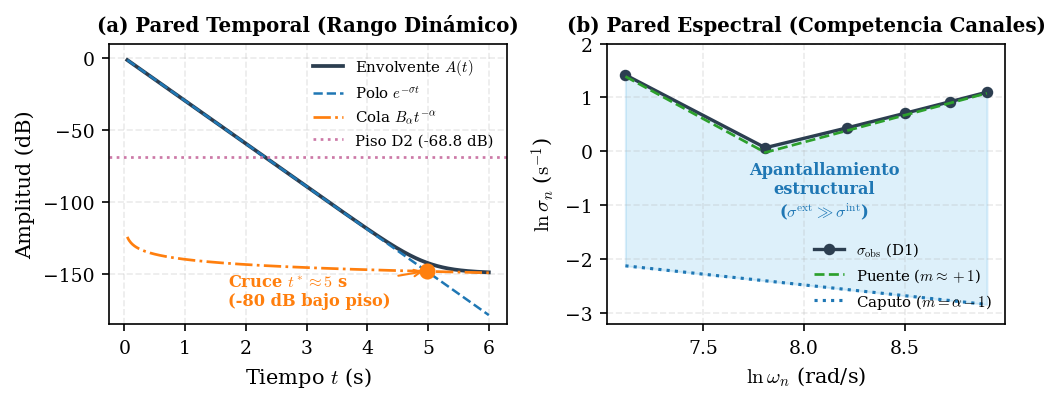

✅ [E4] Guardada: fig/Fig_7_1_Mapa.pdf


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.9, 2.8))

# Panel (a): Pared Temporal
t_map = np.linspace(0.05, 6.0, 400)
sig_m = 3.43
r_m = 1e-7
alpha_m = 0.60
polo_db = 20 * np.log10(np.exp(-sig_m * t_map))
cola_db = 20 * np.log10(r_m * (t_map ** (-alpha_m)))
tot_db = 20 * np.log10(np.exp(-sig_m * t_map) + r_m * (t_map ** (-alpha_m)))

ax1.plot(t_map, tot_db, color=OI_BLACK, lw=1.8, label='Envolvente $A(t)$')
ax1.plot(t_map, polo_db, color=OI_BLUE, ls='--', lw=1.2, label=r'Polo $e^{-\sigma t}$')
ax1.plot(t_map, cola_db, color=OI_ORANGE, ls='-.', lw=1.3, label=r'Cola $B_\alpha t^{-\alpha}$')
ax1.axhline(-68.8, color=OI_PINK, ls=':', lw=1.3, label='Piso D2 (-68.8 dB)')
ax1.scatter([4.98], [-148], color=OI_ORANGE, s=45, zorder=5)
ax1.annotate(r'Cruce $t^*\approx 5$ s' + '\n(-80 dB bajo piso)', xy=(4.98, -148), xytext=(1.7, -172),
             arrowprops=dict(arrowstyle='->', color=OI_ORANGE, lw=1.0), fontsize=7.8, fontweight='bold', color=OI_ORANGE)
ax1.set_title('(a) Pared Temporal (Rango Dinámico)', fontsize=9.5, fontweight='bold')
ax1.set_xlabel('Tiempo $t$ (s)')
ax1.set_ylabel('Amplitud (dB)')
ax1.set_ylim(-185, 10)
ax1.legend(loc='upper right', fontsize=7.2)

# Panel (b): Pared Espectral
n_m = np.arange(1, 7)
w_m = 2 * np.pi * 196.0 * n_m
ln_w = np.log(w_m)
sig_int = 0.12 * ((w_m / w_m[0]) ** (alpha_m - 1.0))
sig_ext = 0.98 * (w_m / w_m[1])
sig_ext[0] = 4.01
sig_tot = sig_int + sig_ext

ax2.plot(ln_w, np.log(sig_tot), 'o-', color=OI_BLACK, lw=1.6, markersize=4.5, label=r'$\sigma_{\mathrm{obs}}$ (D1)')
ax2.plot(ln_w, np.log(sig_ext), '--', color=OI_GREEN, lw=1.3, label=r'Puente ($m \approx +1$)')
ax2.plot(ln_w, np.log(sig_int), ':', color=OI_BLUE, lw=1.5, label=r'Caputo ($m = \alpha-1$)')
ax2.fill_between(ln_w, np.log(sig_int), np.log(sig_tot), color=OI_CYAN, alpha=0.2)
ax2.text(8.1, -1.2, 'Apantallamiento\nestructural\n' + r'($\sigma^{\mathrm{ext}} \gg \sigma^{\mathrm{int}}$)',
         fontsize=7.8, ha='center', color=OI_BLUE, fontweight='bold')
ax2.set_title('(b) Pared Espectral (Competencia Canales)', fontsize=9.5, fontweight='bold')
ax2.set_xlabel(r'$\ln \omega_n$ (rad/s)')
ax2.set_ylabel(r'$\ln \sigma_n$ ($\mathrm{s}^{-1}$)')
ax2.set_ylim(-3.2, 2.0)
ax2.legend(loc='lower right', fontsize=7.2)

plt.tight_layout()
plt.savefig('fig/Fig_7_1_Mapa.pdf')
plt.savefig('fig/Fig_7_1_Mapa_preview.png', dpi=300)
plt.show()
print("✅ [E4] Guardada: fig/Fig_7_1_Mapa.pdf")

In [ ]:
from google.colab import files

zip_name = 'Tesis7_Esquemas_E1_E4.zip'
with zipfile.ZipFile(zip_name, 'w') as zf:
    for fname in sorted(os.listdir('fig')):
        zf.write(os.path.join('fig', fname), arcname=fname)

print("="*75)
print(f"{'ID':<6} | {'Archivo PDF Vectorial':<32} | {'Destino LaTeX'}")
print("="*75)
print(f"{'E1':<6} | {'Fig_5_3_Pipeline.pdf':<32} | {'Sec. 5.2 (fig:pipeline)'}")
print(f"{'E2':<6} | {'Fig_B_1_Cota_R.pdf':<32} | {'Ap. B.1 (fig:cota_cola_polo)'}")
print(f"{'E3':<6} | {'Fig_C_1_Monocordio_Esquema.pdf':<32} | {'Ap. C.2 (fig:monocordio_esquema)'}")
print(f"{'E4':<6} | {'Fig_7_1_Mapa.pdf':<32} | {'Sec. 7.2.2 (fig:mapa_identificabilidad)'}")
print("="*75)

files.download(zip_name)